# Class 2 - Flexible models, honest scores, and the homology trap

**AI in Quantitative Biology (Univ. Milano, 2026) - class 2 of 3, 90 min**
*Goes with `Class 2.pptx` in this folder; slide numbers are the ones of that deck.*

Class 1 ended with a small neural network on the fish toxicity table. Today we ask how far flexible
models really get on such a table and how to score them honestly, then move from molecules to proteins.

| Part | Topic |
|---|---|
| A | Beyond a straight line: kNN and random forests, cross-validation, learning curves (regression) |
| B | A neural network on the same data: what it learns, how big it should be |
| C | Can we tell an enzyme's class from its amino-acid sequence? (classification) |

Part C introduces a trap that is everywhere in biological machine learning: **related sequences
leaking between training and test set**.

| min | Slides | Notebook |
|---|---|---|
| 0-5 | 2-3: deephERG, a toxicity model built on molecular descriptors | |
| 5-23 | | Part A: one split, cross-validation, random forest, learning curves, importance |
| 23-27 | 4-5: Part II, deep networks | |
| 27-42 | | Part B: the MLP, the function it learned, size and regularisation |
| 42-48 | 6-7: featurization, evaluation of classifiers | |
| 48-60 | | C1-C3: the enzymes, amino-acid composition, three classifiers |
| 60-66 | 8-11: the Merck challenge, and why random test sets are too optimistic | |
| 66-76 | | C4: the homology trap |
| 76-86 | 12-15: convolutional networks, or learning the features | Summary |
| 86-90 | buffer, questions | |

Short on time: skip the learning curves in Part A and the regularisation sweep in Part B. The longer
originals, with more exercises and two interactive playgrounds, are `course/t01_toxicity_qsar.ipynb`
and `course/t02_neural_networks_enzymes.ipynb`.

✏️ marks exercises and ❓ questions to discuss with your neighbour: try them yourself first, the solution follows right after.

## Setup

Everything runs on a laptop CPU in a few minutes; no GPU needed. The data are in the `data/`
folder of the course repository. The cell below finds it in the folders above
the notebook.

In [ ]:
# @title Setup: imports, data loading and helpers (run me)
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RNG = 0                                         # fixed seed: everyone gets the same numbers
pd.set_option("display.precision", 3)

import os
from pathlib import Path

def find_data_dir():
    """$QBIO_DATA if set, else the `data/` folder of the course repository (here or above)."""
    if os.environ.get("QBIO_DATA"):
        return Path(os.environ["QBIO_DATA"])
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "qsar_fish_toxicity.csv").exists():
            return p / "data"
    raise FileNotFoundError("Cannot find data/: run the notebook inside the course repository, "
                            "or set QBIO_DATA to the path of its data/ folder")

DATA_DIR = find_data_dir()
print("data from", DATA_DIR)

FISH_COLUMNS = ["CIC0", "SM1_Dz", "GATS1i", "NdsCH", "NdssC", "MLOGP", "LC50"]

def load_fish():
    """Fathead minnow 96 h LC50 for 908 chemicals (UCI QSAR fish toxicity)."""
    return pd.read_csv(DATA_DIR / "qsar_fish_toxicity.csv", sep=";", header=None, names=FISH_COLUMNS)

def load_enzymes():
    """2047 Swiss-Prot enzymes labelled by top-level EC class."""
    return pd.read_csv(DATA_DIR / "enzymes.tsv", sep="\t")

AA = "ACDEFGHIKLMNPQRSTVWY"                     # the 20 standard amino acids

def aa_composition(seq):
    """Fraction of each of the 20 amino acids in `seq` (a vector of length 20)."""
    return np.array([seq.count(a) for a in AA]) / len(seq)

def plot_confusion(y_true, y_pred, labels, title=None):
    """Confusion matrix as a heatmap: rows = true class, normalised per row."""
    from sklearn.metrics import confusion_matrix
    cm = confusion_matrix(y_true, y_pred, labels=labels, normalize="true")
    ax = plt.subplots(figsize=(len(labels) + 2, len(labels) + 1))[1]
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    if title:
        ax.set_title(title)

data from /Users/toni/Sync/teaching/c-courses/2026 AI QBio/classes/data


# Part A - Beyond a straight line

The same data as in class 1: **908 chemicals**, six molecular descriptors, and the measured toxicity to
the fathead minnow (`LC50`, in $-\log_{10}$ mol/L: larger means more toxic).

In [ ]:
fish = load_fish()
X = fish.drop(columns="LC50")
y = fish["LC50"]
fish.head()

,CIC0,SM1_Dz,GATS1i,NdsCH,NdssC,MLOGP,LC50
0,3.260,0.829,1.676,0,1,1.453,3.770
1,2.189,0.580,0.863,0,0,1.348,3.115
2,2.125,0.638,0.831,0,0,1.348,3.531
3,3.027,0.331,1.472,1,0,1.807,3.510
4,2.094,0.827,0.860,0,0,1.886,5.390


## A1 - One split, and two reference points

As in class 1, we hold out 25% of the chemicals as a test set. Two numbers to keep in mind for the rest
of the session: the error of the dumbest possible model, and the score of a linear regression on all six
descriptors.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RNG)
print(len(X_train), "training chemicals,", len(X_test), "test chemicals")

# the dumbest possible model: always predict the training mean
baseline = np.full(len(y_test), y_train.mean())
print(f"baseline  RMSE = {root_mean_squared_error(y_test, baseline):.3f}")

681 training chemicals, 227 test chemicals
baseline  RMSE = 1.399


In [ ]:
lr_all = LinearRegression().fit(X_train, y_train)
pred_all = lr_all.predict(X_test)
print(f"all six:  RMSE = {root_mean_squared_error(y_test, pred_all):.3f}   R2 = {r2_score(y_test, pred_all):.3f}")

all six:  RMSE = 1.045   R2 = 0.442


## A2 - Non-linear models and cross-validation

A straight line may be too simple. Two classic non-linear models:

* **k-nearest neighbours (kNN)**: predict the average LC50 of the *k* most similar training
  chemicals. Similarity = distance in descriptor space, so scaling matters!
* **Random forest (RF)**: average of many decision trees, each trained on a random resample.

A single train/test split is noisy (it depends on which chemicals ended up in the test set).
**5-fold cross-validation** splits the data in 5 parts, uses each part once as test set, and
averages the 5 scores.

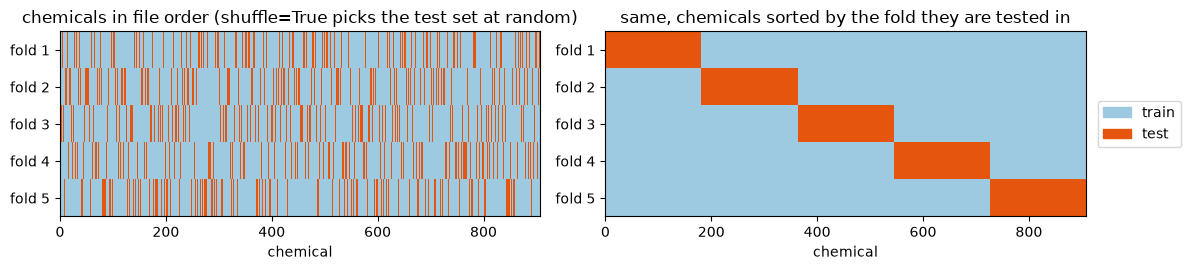

In [ ]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=RNG)

# which chemicals are in the test set of each fold?
fold_of = np.zeros(len(X), dtype=int)
role = np.zeros((cv.get_n_splits(), len(X)))           # 1 = test, 0 = train
for i, (train_idx, test_idx) in enumerate(cv.split(X)):
    role[i, test_idx] = 1
    fold_of[test_idx] = i

from matplotlib.colors import ListedColormap
cmap = ListedColormap(["#9ecae1", "#e6550d"])           # train = blue, test = orange
fig, axes = plt.subplots(1, 2, figsize=(12, 2.8))
axes[0].imshow(role, aspect="auto", cmap=cmap, interpolation="nearest")
axes[0].set_title("chemicals in file order (shuffle=True picks the test set at random)")
axes[1].imshow(role[:, np.argsort(fold_of, kind="stable")], aspect="auto", cmap=cmap, interpolation="nearest")
axes[1].set_title("same, chemicals sorted by the fold they are tested in")
for ax in axes:
    ax.set_yticks(range(5), [f"fold {i + 1}" for i in range(5)])
    ax.set_xlabel("chemical")
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color="#9ecae1", label="train"), Patch(color="#e6550d", label="test")],
               loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    "linear (MLOGP only)": ("MLOGP", LinearRegression()),
    "linear (all)":        (None, LinearRegression()),
    "kNN, k=10 (scaled)":  (None, make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10))),
    "random forest":       (None, RandomForestRegressor(n_estimators=300, random_state=RNG, n_jobs=-1)),
}

results, fold_scores = {}, {}
for name, (cols, model) in models.items():
    Xm = X[[cols]] if cols else X
    r2 = cross_val_score(model, Xm, y, cv=cv, scoring="r2")
    results[name] = (r2.mean(), r2.std())
    fold_scores[name] = r2
    print(f"{name:22s} R2 = {r2.mean():.3f} +/- {r2.std():.3f}")

linear (MLOGP only)    R2 = 0.408 +/- 0.053
linear (all)           R2 = 0.557 +/- 0.043
kNN, k=10 (scaled)     R2 = 0.619 +/- 0.023


random forest          R2 = 0.604 +/- 0.027


Each fold gives its own score. How different are they? And how unusual was the single split of
A1? Let us repeat that split with 200 different random seeds.

200 splits: R2 = 0.566 +/- 0.049, range 0.41 - 0.69
splits worse than ours: 1.5%


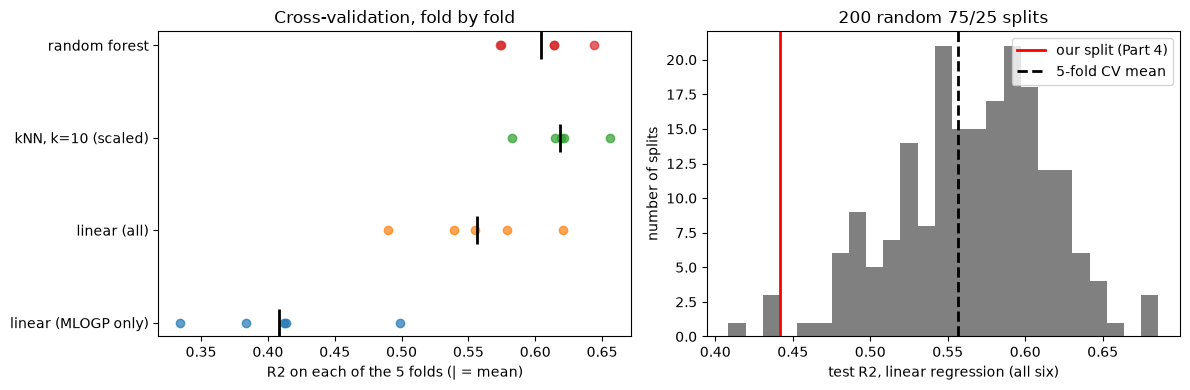

In [ ]:
# @title Support code: fold-by-fold scores and 200 random splits (figure)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for i, (name, r2) in enumerate(fold_scores.items()):
    ax1.plot(r2, np.full(5, i), "o", alpha=0.7)
    ax1.plot(r2.mean(), i, "k|", ms=20, mew=2)
ax1.set_yticks(range(len(fold_scores)), list(fold_scores))
ax1.set_xlabel("R2 on each of the 5 folds (| = mean)")
ax1.set_title("Cross-validation, fold by fold")

split_r2 = []
for seed in range(200):
    Xa_, Xb_, ya_, yb_ = train_test_split(X, y, test_size=0.25, random_state=seed)
    split_r2.append(r2_score(yb_, LinearRegression().fit(Xa_, ya_).predict(Xb_)))
split_r2 = np.array(split_r2)

ax2.hist(split_r2, bins=25, color="grey")
ax2.axvline(r2_score(y_test, pred_all), color="r", lw=2, label="our split (Part 4)")
ax2.axvline(fold_scores["linear (all)"].mean(), color="k", ls="--", lw=2, label="5-fold CV mean")
ax2.set_xlabel("test R2, linear regression (all six)"); ax2.set_ylabel("number of splits")
ax2.set_title("200 random 75/25 splits"); ax2.legend()
plt.tight_layout()
print(f"200 splits: R2 = {split_r2.mean():.3f} +/- {split_r2.std():.3f}, "
      f"range {split_r2.min():.2f} - {split_r2.max():.2f}")
print(f"splits worse than ours: {(split_r2 < r2_score(y_test, pred_all)).mean():.1%}")

❓ Was the split of A1 (the red line, labelled "Part 4" in the figure) representative? Which number would you report for the linear model, and
can you say that the random forest is better than kNN?

**Answer.** No, it was unlucky: R² ≈ 0.44 falls in the worst 2% of the 200 random splits, which
average ≈ 0.57 ± 0.05. Whatever we conclude from one split of 227 chemicals can be off by
±0.1 in R². The cross-validated value (≈ 0.56) agrees with the average over many splits and is the
one to report. Fold to fold, R² varies by about ±0.05 for every model. That is as large as the
differences between kNN, RF and the linear model, so the ranking of the three non-trivial models is
*not* solid. Only "MLOGP alone is worse" is clear.

Let us look at the predictions of the random forest on the held-out test set.

RF test RMSE = 0.965   R2 = 0.524


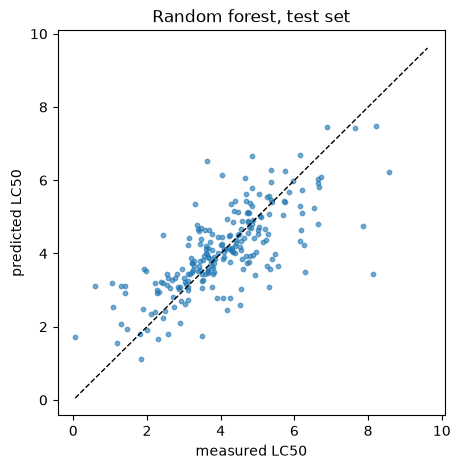

In [ ]:
rf = RandomForestRegressor(n_estimators=300, random_state=RNG, n_jobs=-1).fit(X_train, y_train)
pred_rf = rf.predict(X_test)
print(f"RF test RMSE = {root_mean_squared_error(y_test, pred_rf):.3f}   R2 = {r2_score(y_test, pred_rf):.3f}")

plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred_rf, s=10, alpha=0.6)
lims = [y.min(), y.max()]
plt.plot(lims, lims, "k--", lw=1)
plt.xlabel("measured LC50"); plt.ylabel("predicted LC50"); plt.title("Random forest, test set");

❓ Look at the scatter plot: which chemicals are badly predicted? Is the model better in the middle
or at the extremes?

**Answer.** The predictions are "shrunk" towards the mean: very toxic chemicals are under-predicted
and very non-toxic ones over-predicted. Averaging models (RF, kNN) can never predict outside the
range of their training targets. The most toxic chemicals - the ones a regulator cares about -
are often those with a specific mode of action that six descriptors cannot capture.

Would **more data** help? A **learning curve** trains each model on bigger and bigger subsets and
measures the error on the training data and on held-out data.

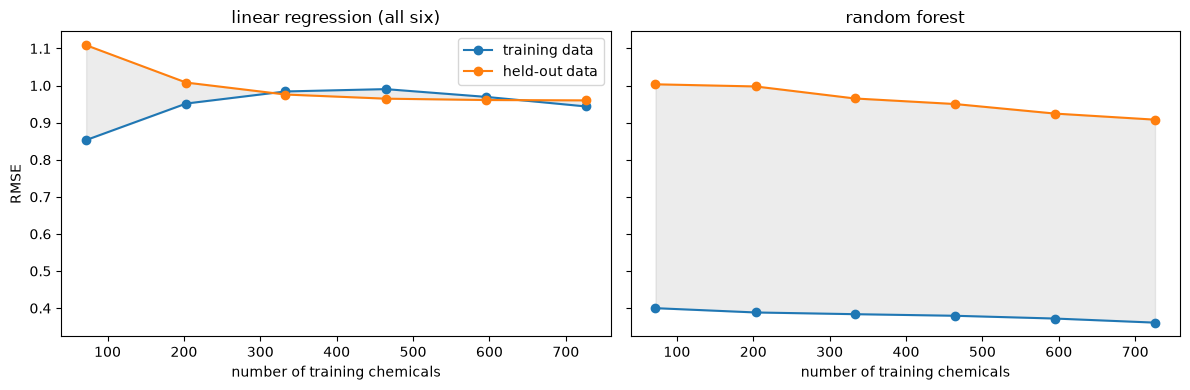

In [ ]:
# @title Support code: learning curves (figure)
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, model) in zip(axes, {
        "linear regression (all six)": LinearRegression(),
        "random forest": RandomForestRegressor(n_estimators=100, random_state=RNG, n_jobs=-1)}.items()):
    sizes, tr, te = learning_curve(model, X, y, cv=cv, train_sizes=np.linspace(0.1, 1, 6),
                                   scoring="neg_root_mean_squared_error")
    ax.plot(sizes, -tr.mean(axis=1), "o-", label="training data")
    ax.plot(sizes, -te.mean(axis=1), "o-", label="held-out data")
    ax.fill_between(sizes, -tr.mean(axis=1), -te.mean(axis=1), alpha=0.15, color="grey")
    ax.set_title(name); ax.set_xlabel("number of training chemicals")
axes[0].set_ylabel("RMSE"); axes[0].legend()
plt.tight_layout()

❓ For which model would testing more chemicals on fish be worth the money?

**Answer.** For the **linear model** the two curves have already met (RMSE ≈ 0.96 on both) after
a few hundred chemicals. It is limited by its own simplicity (high **bias**), and more data will not
help. The **random forest** fits its training data much better than new data (≈ 0.36 vs ≈ 0.91:
high **variance**), and its held-out error is still going down at 726 chemicals. More data would
probably still improve it. The shaded gap is how much the model has memorised.

## A3 - What did the model learn?

**Permutation importance**: shuffle one descriptor in the test set and measure how much the score
drops. If the model relies on that descriptor, scrambling it hurts.

NdssC     0.014
CIC0      0.026
NdsCH     0.088
GATS1i    0.100
SM1_Dz    0.238
MLOGP     0.427
dtype: float64


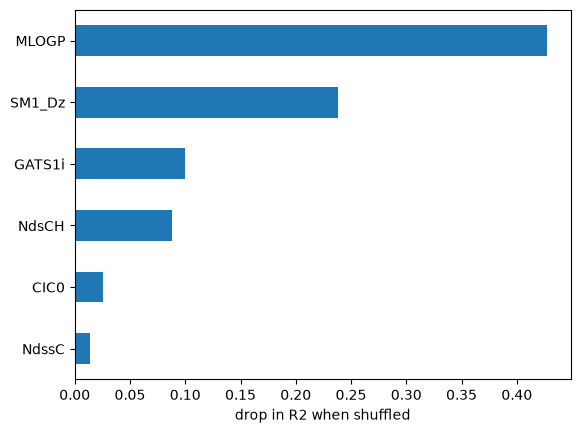

In [ ]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(rf, X_test, y_test, n_repeats=20, random_state=RNG, scoring="r2")
importance = pd.Series(imp.importances_mean, index=X.columns).sort_values()
print(importance)
importance.plot.barh()
plt.xlabel("drop in R2 when shuffled");

❓ Does the random forest agree with the correlations of class 1 (`MLOGP`, r = 0.65)?

**Answer.** Yes: `MLOGP` is by far the most important, followed by `SM1_Dz` and `GATS1i`. The
correlations and the model tell the same biological story: lipophilicity first.

# Part B - A neural network for toxicity

A **multi-layer perceptron (MLP)** is a stack of layers. Each *neuron* computes a weighted sum of its
inputs and passes it through a non-linear *activation* (here ReLU: $\max(0, z)$):

$$ h_j = \mathrm{ReLU}\Big(\sum_i w_{ji} x_i + b_j\Big), \qquad \hat y = \sum_j v_j h_j + c $$

The weights $w, v$ and biases $b, c$ start random and are adjusted step by step (gradient descent)
to reduce the squared error on the training data. With enough hidden neurons an MLP can
approximate any smooth function - which is both its strength and its danger.

```
 6 descriptors  ->  [32 hidden neurons, ReLU]  ->  1 output (LC50)
```

In [ ]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

fish = load_fish()
X, y = fish.drop(columns="LC50"), fish["LC50"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RNG)

mlp = make_pipeline(
    StandardScaler(),                     # neural nets also want scaled inputs
    MLPRegressor(hidden_layer_sizes=(32,), max_iter=3000, random_state=RNG),
)
mlp.fit(X_train, y_train)
print(f"MLP test R2 = {r2_score(y_test, mlp.predict(X_test)):.3f}")

MLP test R2 = 0.512


The network was trained iteratively. `loss_curve_` stores the training loss after each pass over
the data (*epoch*).

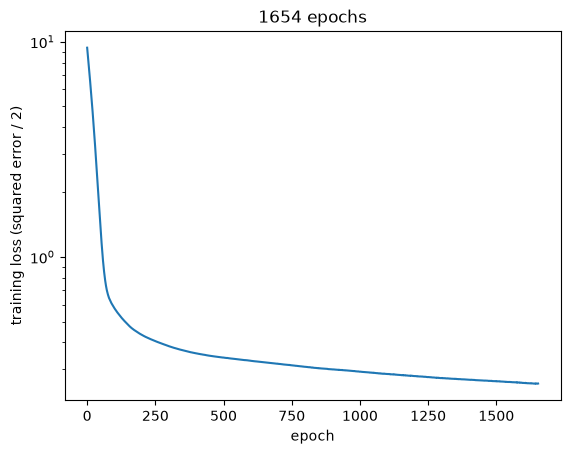

In [ ]:
net = mlp[-1]
plt.plot(net.loss_curve_)
plt.yscale("log")
plt.xlabel("epoch"); plt.ylabel("training loss (squared error / 2)")
plt.title(f"{net.n_iter_} epochs");

✏️ **Exercise B.1.** Compare the MLP with the random forest of Part A using the same 5-fold
cross-validation (`cv` below). Which one wins?

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=RNG)
rf = RandomForestRegressor(n_estimators=300, random_state=RNG, n_jobs=-1)

r2_mlp = cross_val_score(mlp, X, y, cv=cv, scoring="r2")
r2_rf = cross_val_score(rf, X, y, cv=cv, scoring="r2")
print(f"MLP R2 = {r2_mlp.mean():.3f}   RF R2 = {r2_rf.mean():.3f}")

MLP R2 = 0.576   RF R2 = 0.604


### What function did each model learn?

The models live in 6 dimensions, so we cannot draw them. We can take a **slice**: vary `MLOGP` and
keep the other five descriptors fixed at their median. Each curve is the predicted LC50 along that slice.

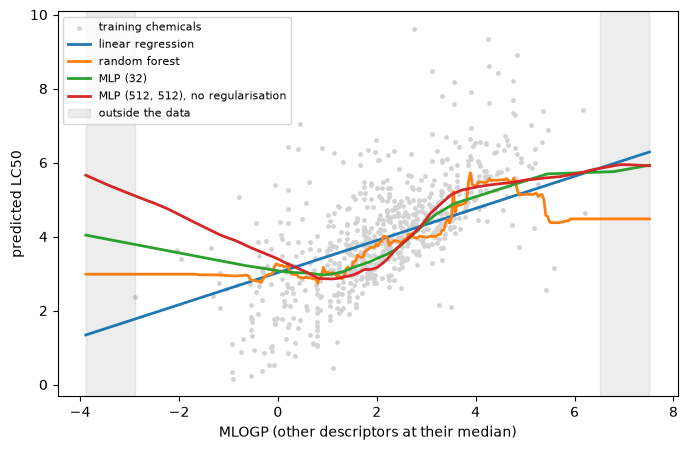

In [ ]:
# @title Support code: the function each model learned (figure)
from sklearn.linear_model import LinearRegression

line = pd.DataFrame(np.tile(X_train.median().values, (300, 1)), columns=X.columns)
line["MLOGP"] = np.linspace(X["MLOGP"].min() - 1, X["MLOGP"].max() + 1, 300)

wide_mlp = make_pipeline(StandardScaler(),
                         MLPRegressor(hidden_layer_sizes=(512, 512), alpha=1e-4,
                                      max_iter=2000, random_state=RNG))
fitted = {
    "linear regression": LinearRegression(),
    "random forest": RandomForestRegressor(n_estimators=300, random_state=RNG, n_jobs=-1),
    "MLP (32)": mlp,                                   # already trained above
    "MLP (512, 512), no regularisation": wide_mlp,
}
plt.figure(figsize=(8, 5))
plt.scatter(X_train["MLOGP"], y_train, s=6, c="lightgrey", label="training chemicals")
for name, m in fitted.items():
    if m is not mlp:
        m.fit(X_train, y_train)
    plt.plot(line["MLOGP"], m.predict(line), lw=2, label=name)
plt.axvspan(line["MLOGP"].min(), X["MLOGP"].min(), color="k", alpha=0.07)
plt.axvspan(X["MLOGP"].max(), line["MLOGP"].max(), color="k", alpha=0.07, label="outside the data")
plt.xlabel("MLOGP (other descriptors at their median)"); plt.ylabel("predicted LC50")
plt.legend(fontsize=8);

❓ Describe the shape of each curve. What happens outside the range of the data (grey bands)?

**Answer.** Linear regression is a straight line everywhere. The random forest is a **staircase**:
each tree cuts the axis into intervals and predicts a constant in each, and beyond the data it goes
**flat** (it can never predict outside the range of the training LC50). The MLP is made of ReLUs,
so it is **piecewise linear**: smooth bends inside the data, then it continues as a straight line
outside, extrapolating in whatever direction the last piece pointed. Both MLPs bend **upwards** at low MLOGP,
predicting that very hydrophilic chemicals are *more* toxic: there are few training chemicals there,
the curve is not constrained, and the result is biologically implausible. The big unregularised
network bends more and has small wiggles where it follows individual chemicals: overfitting, seen directly.
None of the models can be trusted in the grey bands; QSAR guidelines call the region where a
model is valid its **applicability domain**.

### How big should the network be?

We train networks with two hidden layers of increasing width and compare the R² on the
**training** set with the R² on the **test** set.

,train R2,test R2
width,,
1,0.599,0.416
2,0.624,0.429
4,0.650,0.457
8,0.704,0.473
32,0.875,0.414
128,0.891,0.511
512,0.934,0.465


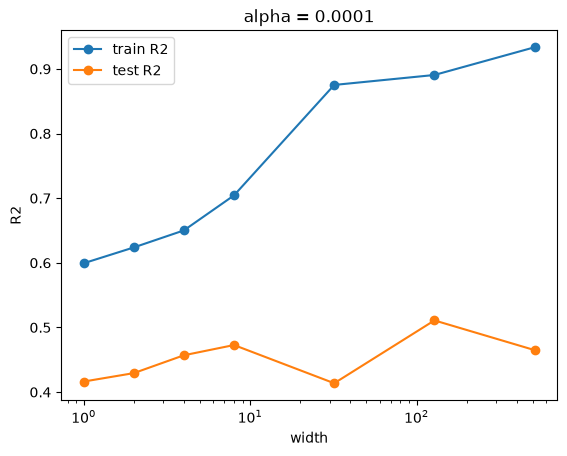

In [ ]:
sizes = [1, 2, 4, 8, 32, 128, 512]

def size_sweep(alpha):
    """Train/test R2 for 2-hidden-layer MLPs of each width; alpha = L2 penalty on the weights."""
    rows = []
    for h in sizes:
        m = make_pipeline(StandardScaler(),
                          MLPRegressor(hidden_layer_sizes=(h, h), alpha=alpha,
                                       max_iter=2000, random_state=RNG))
        m.fit(X_train, y_train)
        rows.append((h, r2_score(y_train, m.predict(X_train)), r2_score(y_test, m.predict(X_test))))
    return pd.DataFrame(rows, columns=["width", "train R2", "test R2"]).set_index("width")

sweep = size_sweep(alpha=1e-4)          # almost no regularisation
sweep.plot(logx=True, marker="o")
plt.ylabel("R2"); plt.title("alpha = 0.0001");
sweep

❓ What happens to the gap between training and test R² as the network grows? What is this called?

✏️ **Exercise B.2.** `alpha` adds a penalty on large weights (*L2 regularisation*, "weight decay").
Run `size_sweep(alpha=1.0)` and compare with the plot above.

,train R2,test R2
width,,
1,0.590,0.412
2,0.623,0.430
4,0.653,0.464
8,0.704,0.497
32,0.784,0.524
128,0.800,0.553
512,0.773,0.559


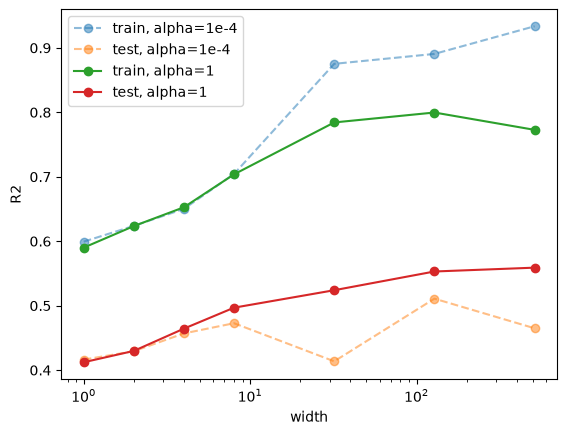

In [ ]:
sweep_reg = size_sweep(alpha=1.0)
ax = sweep.plot(logx=True, marker="o", style="--", alpha=0.5)
sweep_reg.plot(logx=True, marker="o", ax=ax)
plt.legend(["train, alpha=1e-4", "test, alpha=1e-4", "train, alpha=1", "test, alpha=1"])
plt.ylabel("R2");
sweep_reg

**Answer.** Without regularisation, the bigger networks fit the training set better and better
(train R² up to ≈ 0.93) while the test R² does not improve: this is **overfitting** - the network
memorises the 681 training chemicals, noise included. With `alpha=1.0` the training R² stays
lower (≈ 0.8), the gap shrinks, and the large networks generalise best (test R² ≈ 0.55).
On a small table of 6 descriptors, an MLP does **not** beat a random forest (≈ 0.58 vs ≈ 0.60
in cross-validation). Neural networks shine with large data and with raw, structured inputs such as
sequences and images - which is where we go next.

# Part C - Can we tell an enzyme's class from its sequence?

Enzymes are classified by the reaction they catalyse into **EC (Enzyme Commission) classes**:

| EC | class | reaction |
|---|---|---|
| 1 | Oxidoreductases | transfer of electrons (redox) |
| 2 | Transferases | transfer of a group (methyl, phosphate, ...) |
| 3 | Hydrolases | cleavage by water |
| 4 | Lyases | cleavage without water or oxidation |
| 5 | Isomerases | rearrangement within a molecule |
| 6 | Ligases | joining two molecules, using ATP |

Our dataset contains **2047 enzymes** from UniProt/Swiss-Prot (manually reviewed), from five model
organisms (human, *E. coli*, baker's yeast, *Arabidopsis*, *B. subtilis*), about 350 per class.
Each enzyme also has its **protein family** (groups of evolutionarily related proteins).

## C1 - Meet the data

In [ ]:
enz = load_enzymes()
print(enz.shape)
enz.head()

(2047, 10)


,accession,entry_name,protein_name,organism,ec,ec_class,ec_name,family,length,sequence
0,A8MRX0,GSOX5_ARATH,Flavin-containing monooxygenase FMO GS-OX5,Arabidopsis thaliana,1.14.13.237,1,Oxidoreductase,FMO family,459,MAPARTRVNSLNVAVIGAGAAGLVAARELRRENHTVVVFERDSKVG...
1,A9X4U2,HSDD3_ARATH,3beta-hydroxysteroid-dehydrogenase/decarboxyla...,Arabidopsis thaliana,1.1.1.170,1,Oxidoreductase,3-beta-HSD family,561,MDEDSVHGDSHLKTCVVLGGRGFIGRSLVSRLLRLGNWTVRVADSG...
2,F4ILF8,P4H13_ARATH,Prolyl 4-hydroxylase 13,Arabidopsis thaliana,1.14.11.2,1,Oxidoreductase,P4HA family,274,MRSYGKEKKLVFPYVFIACCFFLAIFGFCFFNLFSQGISFSEIPTT...
3,F4K2M8,JMJ31_ARATH,Lysine-specific demethylase JMJ31,Arabidopsis thaliana,1.14.11.-,1,Oxidoreductase,JARID1 histone demethylase family,549,MPTGCEFPMIKTFENALTAADFESTVELTNFPAVFRGCASVWDAYS...
4,F4KAV2,AKB1D_ARATH,DNA N,Arabidopsis thaliana,1.14.11.51,1,Oxidoreductase,AlkB family,442,MLNSIHRSFHLTSRHQIVLRLCSPSASRTIMSSSPHSPIPKTHTAS...


In [ ]:
print(enz["ec_name"].value_counts(), "\n")
pd.crosstab(enz["organism"], enz["ec_name"])

ec_name
Oxidoreductase    350
Transferase       350
Hydrolase         350
Lyase             350
Isomerase         350
Ligase            297
Name: count, dtype: int64 



ec_name,Hydrolase,Isomerase,Ligase,Lyase,Oxidoreductase,Transferase
organism,,,,,,
Arabidopsis thaliana,121,100,67,118,128,149
Bacillus subtilis,37,55,63,63,53,32
Escherichia coli,32,73,64,65,49,39
Homo sapiens,120,72,58,57,88,98
Saccharomyces cerevisiae,40,50,45,47,32,32


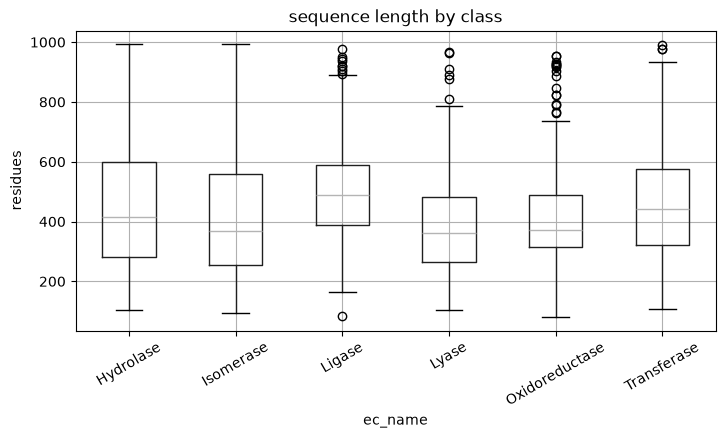

In [ ]:
classes = sorted(enz["ec_name"].unique())
enz.boxplot(column="length", by="ec_name", figsize=(8, 4), rot=30)
plt.suptitle(""); plt.title("sequence length by class"); plt.ylabel("residues");

## C2 - Amino-acid composition

The simplest way to turn a sequence of any length into a fixed-size vector: the **fraction of
each of the 20 amino acids**. This forgets the order completely.

In [ ]:
comp = pd.DataFrame(np.vstack(enz["sequence"].map(aa_composition)), columns=list(AA))
comp.head()

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
0,0.063,0.009,0.063,0.070,0.044,0.065,0.033,0.044,0.044,0.072,0.017,0.041,0.061,0.035,0.065,0.072,0.044,0.096,0.020,0.044
1,0.062,0.016,0.059,0.043,0.078,0.066,0.023,0.053,0.053,0.109,0.014,0.030,0.027,0.025,0.050,0.103,0.048,0.087,0.016,0.036
2,0.055,0.022,0.051,0.066,0.084,0.066,0.026,0.051,0.062,0.077,0.015,0.044,0.047,0.040,0.047,0.077,0.058,0.051,0.011,0.051
3,0.077,0.016,0.062,0.077,0.049,0.044,0.038,0.044,0.049,0.111,0.029,0.044,0.044,0.031,0.046,0.106,0.038,0.055,0.015,0.027
4,0.034,0.016,0.054,0.061,0.041,0.063,0.032,0.063,0.057,0.084,0.020,0.048,0.059,0.036,0.075,0.124,0.059,0.052,0.007,0.016


Is any amino acid enriched in a class? We compare each class's mean composition with the overall
mean, on a $\log_2$ scale (+1 = twice as frequent).

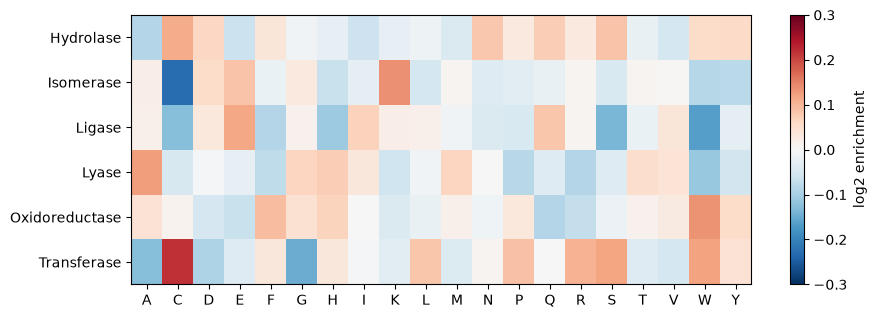

In [ ]:
class_mean = comp.groupby(enz["ec_name"]).mean()
enrichment = np.log2(class_mean / comp.mean())

plt.figure(figsize=(10, 3.5))
plt.imshow(enrichment, cmap="RdBu_r", vmin=-0.3, vmax=0.3, aspect="auto")
plt.colorbar(label="log2 enrichment")
plt.xticks(range(20), AA); plt.yticks(range(len(classes)), enrichment.index);

❓ How large are the differences in composition between classes? What do you expect for a classifier?

**Answer.** The enrichments are tiny (within ±0.25 on a log2 scale, i.e. < 20%) and a PCA map
of the compositions shows the six classes overlapping completely. Composition carries only a faint signal about the catalysed
reaction: expect a classifier to do better than chance, but not much. (Some enrichments have a
story: Cys is enriched among transferases because ~15% of them transfer ubiquitin (EC 2.3.2.x,
e.g. RING-type E3 ligases), whose zinc-binding domains contain twice the average Cys.)

## C3 - Classifiers

Features: the 20 composition values plus log(length). We measure **accuracy** (fraction of
correct predictions) with stratified 5-fold cross-validation (each fold keeps the class
proportions). With 6 balanced classes, **random guessing gives about 1/6 = 0.17**.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

Xe = comp.assign(log_length=np.log(enz["length"]))
ye = enz["ec_name"]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG)

classifiers = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "random forest": RandomForestClassifier(n_estimators=300, random_state=RNG, n_jobs=-1),
    "MLP (64)": make_pipeline(StandardScaler(),
                              MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, early_stopping=True,
                                            max_iter=500, random_state=RNG)),
}
acc_random = {}
for name, clf in classifiers.items():
    acc_random[name] = cross_val_score(clf, Xe, ye, cv=skf, scoring="accuracy").mean()
    print(f"{name:20s} accuracy = {acc_random[name]:.3f}")

logistic regression  accuracy = 0.291


random forest        accuracy = 0.398


MLP (64)             accuracy = 0.294


Accuracy hides *which* classes get confused. A **confusion matrix** shows, for each true class (row),
how the predictions are distributed (columns). `cross_val_predict` gives one out-of-fold prediction
per enzyme.

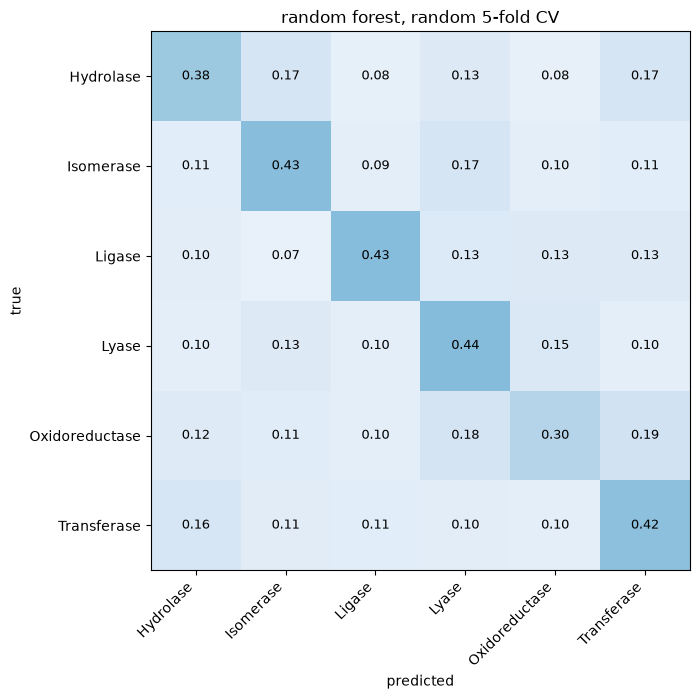

In [ ]:
pred_rf = cross_val_predict(classifiers["random forest"], Xe, ye, cv=skf)
plot_confusion(ye, pred_rf, classes, title="random forest, random 5-fold CV");

❓ Which class is easiest to recognise, which is hardest? Any idea why?

**Answer.** Look at the diagonal: no class is easy (recall ≈ 0.30-0.45 each) and the errors
spread over all columns. Oxidoreductases are the hardest: a huge and chemically diverse class
(NAD-, FAD-, heme-, metal-dependent enzymes in many unrelated folds) with no common composition.
EC classes describe the *chemistry* of the reaction, which evolution has invented many times in
unrelated folds, so composition is a weak proxy for it.

## C4 - The homology trap

Proteins of the same **family** share a common ancestor and often have similar sequences - and
similar compositions. With a random split, a test enzyme usually has a close relative
(e.g. the same enzyme from another organism) in the training set, and the model can just
"recognise the family" instead of learning anything general.

A fairer test for a *new* kind of enzyme: keep **whole families** out of the training set.
`StratifiedGroupKFold` does this - all members of a group end up in the same fold.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

print(enz["family"].nunique(), "families;", (enz["family"].value_counts() > 1).sum(), "with more than one member")
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RNG)
groups = enz["family"]

1102 families; 409 with more than one member


✏️ **Exercise C4.1.** Repeat the cross-validation of the three classifiers with `cv=sgkf` and
`groups=groups` (pass it as `cross_val_score(..., groups=groups)`), and print both accuracies
side by side.

In [ ]:
for name, clf in classifiers.items():
    acc_family = cross_val_score(clf, Xe, ye, cv=sgkf, groups=groups, scoring="accuracy").mean()
    print(f"{name:20s} random split = {acc_random[name]:.3f}   family split = {acc_family:.3f}")

logistic regression  random split = 0.291   family split = 0.270


random forest        random split = 0.398   family split = 0.306


MLP (64)             random split = 0.294   family split = 0.265


❓ Which model loses the most when families are held out, and why? Which number would you report
in a paper claiming "our model predicts the class of newly discovered enzymes"?

**Answer.** The random forest drops the most (≈ 0.40 → 0.30): it is the most flexible model and
partly works as a "find the relative" lookup table. Logistic regression and the MLP drop less
because they were learning less family-specific detail in the first place. For new enzymes, the
family-split number is the honest one. The random-split number answers a different question
("can I annotate a new member of a family I already know?") - for which a BLAST search against
annotated sequences would beat all of these models.

Where exactly does the inflated random-split accuracy come from? For each enzyme, count how many
members of its family were in the **training folds** when it was predicted (in the random 5-fold CV
of C3), and compare the accuracy of the random forest across these groups.

                        mean  size
relatives in training             
0                      0.325   781
1                      0.351   441
2-3                    0.434   429
4+                     0.553   396


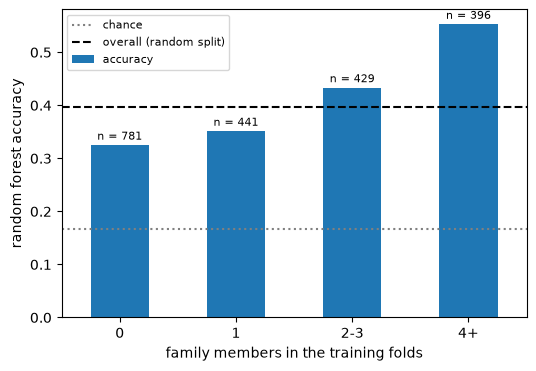

In [ ]:
# @title Support code: accuracy vs number of relatives in training (figure)
fold = np.zeros(len(enz), dtype=int)
for i, (_, test_idx) in enumerate(skf.split(Xe, ye)):
    fold[test_idx] = i
fam = enz["family"].fillna("").values
n_relatives = np.array([0 if fam[j] == "" else ((fam == fam[j]) & (fold != fold[j])).sum()
                        for j in range(len(enz))])
correct = (pred_rf == ye.values)

bins = pd.cut(n_relatives, [-1, 0, 1, 3, 100], labels=["0", "1", "2-3", "4+"])
by_rel = pd.DataFrame({"relatives in training": bins, "correct": correct}) \
           .groupby("relatives in training", observed=True)["correct"].agg(["mean", "size"])
print(by_rel)

ax = by_rel["mean"].plot.bar(rot=0, color="tab:blue", figsize=(6, 4), label="accuracy")
for i, (acc, n) in enumerate(zip(by_rel["mean"], by_rel["size"])):
    ax.text(i, acc + 0.01, f"n = {n}", ha="center", fontsize=8)
ax.axhline(1 / 6, color="grey", ls=":", label="chance")
ax.axhline(acc_random["random forest"], color="k", ls="--", label="overall (random split)")
ax.set_ylabel("random forest accuracy"); ax.set_xlabel("family members in the training folds")
ax.legend(fontsize=8);

❓ What does this plot say about the random-split accuracy?

**Answer.** Accuracy grows with the number of relatives in the training set. Enzymes with no relative
in training get ≈ 0.33, close to the family-split number (≈ 0.31), while those with 4 or more
relatives get ≈ 0.55: the random forest is largely recognising the family.
The random-split accuracy is an average over these groups, so it depends on how many relatives the
dataset happens to contain, not only on how good the model is.

## Summary

* One train/test split is a noisy estimate (R² 0.44 here, against ≈ 0.57 on average over 200 splits);
  **cross-validation** uses every chemical once as test data and is the number to report.
* Non-linear models (kNN, random forest) gain a little over linear regression (R² ≈ 0.56 → 0.60), and
  the fold-to-fold noise is as large as the differences between them.
* A **learning curve** says whether more data would help: not for the linear model (limited by its
  simplicity), probably yes for the random forest (which still memorises).
* An MLP is a flexible function approximator; on a small table it overfits easily, needs scaled
  inputs and regularisation, and does not beat a random forest. No model can be trusted outside the
  range of its training data (its **applicability domain**).
* **Data mining before modelling** told us what to expect: the enzyme classes barely differ in
  composition, and models got 0.25-0.40 accuracy (chance: 0.17).
* **How you split matters as much as which model you use.** Related sequences across the
  train/test boundary inflate the scores; split by family (or by sequence identity) to estimate
  performance on genuinely new proteins.
* Composition throws away the **order** of the residues. Next class: a neural network that reads
  the sequence residue by residue.

### If you have time

✏️ Replace composition by **dipeptide** frequencies (400 features: AA, AC, ..., YY) and redo the
random vs family comparison for the random forest. Does the gap grow or shrink?

In [ ]:
import itertools
DIPEPTIDES = ["".join(p) for p in itertools.product(AA, repeat=2)]
index = {dp: i for i, dp in enumerate(DIPEPTIDES)}

def dipeptide_composition(seq):
    v = np.zeros(len(DIPEPTIDES))
    for i in range(len(seq) - 1):
        v[index[seq[i:i + 2]]] += 1
    return v / (len(seq) - 1)

Xd = np.vstack(enz["sequence"].map(dipeptide_composition))
rf = classifiers["random forest"]
print(f"random split: {cross_val_score(rf, Xd, ye, cv=skf).mean():.3f}")
print(f"family split: {cross_val_score(rf, Xd, ye, cv=sgkf, groups=groups).mean():.3f}")

random split: 0.376


family split: 0.283


**Answer.** Dipeptides do not help (≈ 0.38 random, ≈ 0.28 family split, vs 0.40 / 0.31 with
composition): 400 noisy features for 2047 proteins is a lot, and the leakage gap stays ≈ 0.09.
More features is not the same as more information.

## References and data sources

**Data**

* `qsar_fish_toxicity.csv`: 908 compounds, 96-h LC50 for the fathead minnow (*Pimephales promelas*) with six molecular descriptors (UCI Machine Learning Repository, "QSAR fish toxicity"; Cassotti et al. 2015).
* Enzyme and targeting tables: reviewed entries of UniProtKB/Swiss-Prot (UniProt Consortium 2023), downloaded with the UniProt REST API on 2026-11-10 from human, *E. coli* K-12, yeast, *Arabidopsis* and *B. subtilis*; Swiss-Prot changes at every release, so the committed TSVs are the reference. See `course/README.md` and `data_prep/`.

**Further reading**

* Kapoor S, Narayanan A (2023). Leakage and the reproducibility crisis in machine-learning-based science. *Patterns* 4:100804. [doi:10.1016/j.patter.2023.100804](https://doi.org/10.1016/j.patter.2023.100804) — the vocabulary for the leakage in Part C
* Yu T, Cui H, Li JC, et al. (2023). Enzyme function prediction using contrastive learning. *Science* 379:1358–1363. [doi:10.1126/science.adf2465](https://doi.org/10.1126/science.adf2465) — CLEAN, a recent EC-number predictor: composition alone genuinely cannot do this task
* Lin Z, Akin H, Rao R, et al. (2023). Evolutionary-scale prediction of atomic-level protein structure with a language model. *Science* 379:1123–1130. [doi:10.1126/science.ade2574](https://doi.org/10.1126/science.ade2574) — the protein language model used in extra03